# Women vs Men: A public dataset drawn from the 2012 U.S. Army Anthropometric Survey.

**Topic:** Using body measurement data from U.S. military personnel (**ANSUR II**), we predict gender (female or male) based on body measurements and compare a Decision Tree with **Bagging**.

## 0 · Imports

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

import sklearn
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, precision_recall_fscore_support, roc_auc_score)

RANDOM_STATE = 42
DATA_DIR = Path("data")        
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.9.1


## 1 · Part A: Load the ANSUR II dataset

1. **The data is split into two separate files** (one for men, one for women), and both contain a "Gender" column. The identifier column is labeled `subjectid` in one file and `SubjectId` in the other; therefore, we will convert all column names to lowercase to ensure they match correctly.
2. **File encoding:** The ANSUR files contain non-UTF-8 characters, which may cause errors if read using default settings; consequently, we will load them using `encoding="latin-1"`.
4. **Limited data sample:** The ANSUR II dataset consists exclusively of U.S. Army personnel (rather than the general population). For instance, the Army's height and weight entry standards influence the distributions. Therefore, the findings should not be generalized to the entire population.

In [2]:
def find_ansur_files(folder=DATA_DIR):
    found = []
    for d in (folder, Path(".")):
        if d.exists():
            found += [p for p in d.rglob("*.csv") if "ansur" in p.name.lower()]
    return sorted(set(found))


files = find_ansur_files()

frames = []
for path in files:
    part = pd.read_csv(path, encoding="latin-1")
    part.columns = part.columns.str.strip().str.lower()     
    print(f"{path.name:40s} rows = {len(part):5d} | columns = {part.shape[1]}")
    frames.append(part)

all_columns = set().union(*[set(f.columns) for f in frames])
common_columns = set.intersection(*[set(f.columns) for f in frames])
print("\nColumns present in only some files (dropped when merging):", sorted(all_columns - common_columns))

ansur = pd.concat(frames, join="inner", ignore_index=True)
print("Merged shape:", ansur.shape)

ANSUR II FEMALE Public.csv               rows =  1986 | columns = 108
ANSUR II MALE Public.csv                 rows =  4082 | columns = 108

Columns present in only some files (dropped when merging): []
Merged shape: (6068, 108)


## 2 · Part B: Preprocess and clean the dataset

1. **The question is ambiguous:** The terms "preprocessing and cleaning" do not specify which actions are to be performed or for what purpose. Since the subsequent sections involve gender classification, we define the **target** variable as the `gender` column: Female = 0, Male = 1.
2. **Identifier and administrative columns constitute data leakage:** Columns such as `subjectid`, `installation`, `component`, `branch`, `primarymos` (job specialty), `date`, and the like are not physical body measurements; however, they could inadvertently reveal gender (for instance, certain job specialties or specific ranges of ID numbers might be more common for one gender). A model utilizing these features would achieve "lucky" correct predictions without actually learning anything about physical body characteristics. Therefore, we retain only the **body measurements**. The columns `age`, `heightin`, and `weightlbs` are also removed (age is not a body measurement, while the latter two are simply duplicates of `stature` and `weightkg` expressed in different units).
3. **Units:** In the ANSUR II dataset, measurements are provided in **millimeters**, and `weightkg` is recorded in **tenths of a kilogram** (e.g., a value of 800 represents 80 kg). For the purpose of visualization, we convert height into centimeters. While the specific scale is not critical for decision trees, consistent numerical units are necessary for accurate comparisons.
4. **Outliers:** Extreme values ​​in body measurements typically represent actual individuals rather than errors; furthermore, decision trees are robust against such outliers. Consequently, we remove only **impossible values** (e.g., height measurements falling outside a logical range), while statistical outliers are merely noted/reported. 5. **Decisions that rely on data** (such as imputing missing values ​​using the median) must be performed after the split and based *only* on the training set. In this stage, only rules that are independent of the data distribution—such as removing duplicate columns or rows, or eliminating invalid entries—should be applied prior to the split.

1. Basic inspection

In [3]:
print("Shape:", ansur.shape)
print("\nGender counts (raw):")
print(ansur["gender"].value_counts())

Shape: (6068, 108)

Gender counts (raw):
gender
Male      4082
Female    1986
Name: count, dtype: int64


Normalise the label text

In [4]:
ansur["gender"] = ansur["gender"].astype(str).str.strip().str.title()
assert set(ansur["gender"].unique()) == {"Female", "Male"}, ansur["gender"].unique()

2. Drop identifier / administrative / non-body columns (leakage risk)

In [5]:
NON_BODY_COLS = ["subjectid", "date", "installation", "component", "branch", "primarymos",
                 "subjectsbirthlocation", "subjectnumericrace", "dodrace", "ethnicity",
                 "writingpreference", "age", "heightin", "weightlbs"]
dropped = [c for c in NON_BODY_COLS if c in ansur.columns]
ansur_clean = ansur.drop(columns=dropped)
print("\nDropped non-body columns:", dropped)


Dropped non-body columns: ['subjectid', 'date', 'installation', 'component', 'branch', 'primarymos', 'subjectsbirthlocation', 'subjectnumericrace', 'dodrace', 'ethnicity', 'writingpreference', 'age', 'heightin', 'weightlbs']


3. Keep only numeric body measurements + the label

In [6]:
non_numeric = [c for c in ansur_clean.columns if c != "gender" and not pd.api.types.is_numeric_dtype(ansur_clean[c])]
print("Non-numeric columns still present (dropped):", non_numeric)
ansur_clean = ansur_clean.drop(columns=non_numeric)

Non-numeric columns still present (dropped): []


4. Missing values: drop columns with > 5 % missing, then rows with any missing value 

In [7]:
missing_share = ansur_clean.isna().mean()
sparse_cols = missing_share[missing_share > 0.05].index.tolist()
ansur_clean = ansur_clean.drop(columns=sparse_cols)
rows_before = len(ansur_clean)
ansur_clean = ansur_clean.dropna()
print(f"Columns dropped for > 5% missing: {sparse_cols}")
print(f"Rows dropped for missing values : {rows_before - len(ansur_clean)}")

Columns dropped for > 5% missing: []
Rows dropped for missing values : 0


5. Exact duplicate records

In [8]:
n_dup = int(ansur_clean.duplicated().sum())
ansur_clean = ansur_clean.drop_duplicates()
print(f"Duplicate rows removed         : {n_dup}")

Duplicate rows removed         : 0


6. Impossible values (rule-based, independent of the data distribution)

In [9]:
impossible = ~ansur_clean["stature"].between(1300, 2200)          # stature in mm
print(f"Rows with impossible stature   : {int(impossible.sum())}")
ansur_clean = ansur_clean[~impossible].reset_index(drop=True)

Rows with impossible stature   : 0


7. Statistical outliers are only REPORTED (they are real people; trees are robust)

In [10]:
feature_cols = [c for c in ansur_clean.columns if c != "gender"]
z = (ansur_clean[feature_cols] - ansur_clean[feature_cols].mean()) / ansur_clean[feature_cols].std()
print(f"Cells with |z| > 5 (kept, not removed): {int((z.abs() > 5).sum().sum())}")

Cells with |z| > 5 (kept, not removed): 3


8. Target: Women = 0, Men = 1

In [11]:
class_names = ["Women", "Men"]
y = (ansur_clean["gender"] == "Male").astype(int)

In [12]:
print(f"\nFinal dataset: {len(ansur_clean)} people, {len(feature_cols)} body measurements")
print(f"Women: {(y == 0).sum()} ({(y == 0).mean():.1%}) | Men: {(y == 1).sum()} ({(y == 1).mean():.1%})")
ansur_clean.head()


Final dataset: 6068 people, 93 body measurements
Women: 1986 (32.7%) | Men: 4082 (67.3%)


,abdominalextensiondepthsitting,acromialheight,acromionradialelength,anklecircumference,axillaheight,balloffootcircumference,balloffootlength,biacromialbreadth,bicepscircumferenceflexed,bicristalbreadth,...,waistbacklength,waistbreadth,waistcircumference,waistdepth,waistfrontlengthsitting,waistheightomphalion,weightkg,wristcircumference,wristheight,gender
0,231,1282,301,204,1180,222,177,373,315,263,...,406,295,850,217,345,942,657,152,756,Female
1,194,1379,320,207,1292,225,178,372,272,250,...,422,254,708,168,329,1032,534,155,815,Female
2,183,1369,329,233,1271,237,196,397,300,276,...,419,269,727,159,367,1035,663,162,799,Female
3,261,1356,306,214,1250,240,188,384,364,276,...,451,302,923,235,371,999,782,173,818,Female
4,309,1303,308,214,1210,217,182,378,320,336,...,452,405,1163,300,380,911,886,152,762,Female


## 3 · Part C: Heights of women and men on the same plot

1. **"Higher" and "more right" are ambiguous:** In a histogram, "higher" could refer to **taller bars** (a greater count) or a **larger value**; "more right" implies that the distribution has shifted **toward the right side of the axis** (toward larger values). We interpret Question C-1 as "Why are the bars for men taller?" and Question C-2 as "Why is the distribution for men shifted further to the right?"
2. **A fair comparison requires a density plot:** When the number of men and women differs, a frequency-based (count) histogram conflates sample size with the shape of the distribution. Therefore, we will plot both: one based on counts and one based on density.
3. **Which column represents "height"?** Use `stature` (height measured in millimeters); the `heightin` column is not used here.

In [13]:
height_cm = ansur_clean["stature"] / 10         
women = height_cm[y == 0]
men = height_cm[y == 1]

1. counts: bar heights depend on how many people are in each group
2. density: removes the effect of different group sizes, shows only the shape/location

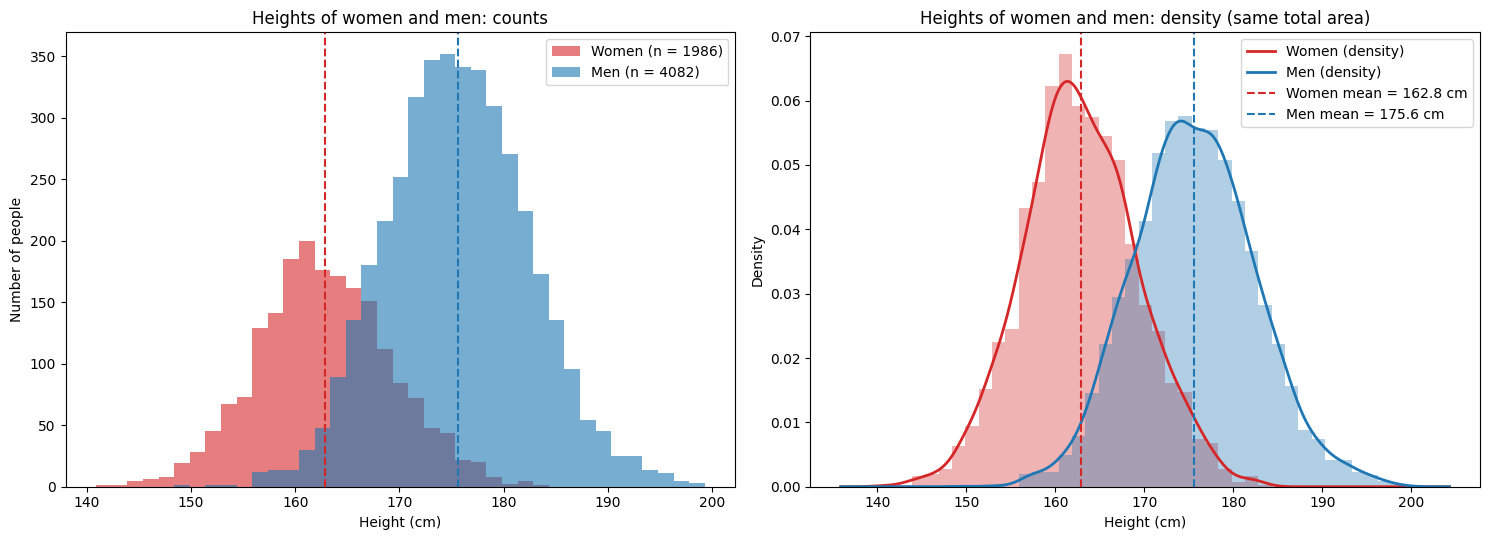

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
bins = np.linspace(height_cm.min(), height_cm.max(), 40)
grid = np.linspace(height_cm.min() - 5, height_cm.max() + 5, 400)

axes[0].hist(women, bins=bins, alpha=0.6, color="tab:red", label=f"Women (n = {len(women)})")
axes[0].hist(men, bins=bins, alpha=0.6, color="tab:blue", label=f"Men (n = {len(men)})")
axes[0].axvline(women.mean(), color="tab:red", linestyle="--")
axes[0].axvline(men.mean(), color="tab:blue", linestyle="--")
axes[0].set_title("Heights of women and men: counts")
axes[0].set_xlabel("Height (cm)")
axes[0].set_ylabel("Number of people")
axes[0].legend()

axes[1].hist(women, bins=bins, density=True, alpha=0.35, color="tab:red")
axes[1].hist(men, bins=bins, density=True, alpha=0.35, color="tab:blue")
axes[1].plot(grid, gaussian_kde(women)(grid), color="tab:red", linewidth=2, label="Women (density)")
axes[1].plot(grid, gaussian_kde(men)(grid), color="tab:blue", linewidth=2, label="Men (density)")
axes[1].axvline(women.mean(), color="tab:red", linestyle="--", label=f"Women mean = {women.mean():.1f} cm")
axes[1].axvline(men.mean(), color="tab:blue", linestyle="--", label=f"Men mean = {men.mean():.1f} cm")
axes[1].set_title("Heights of women and men: density (same total area)")
axes[1].set_xlabel("Height (cm)")
axes[1].set_ylabel("Density")
axes[1].legend()

plt.tight_layout()
plt.show()

In [23]:
summary = pd.DataFrame({"Women": women.describe(), "Men": men.describe()}).T[["count", "mean", "std", "min", "50%", "max"]]
display(summary.round(1))

pooled_sd = np.sqrt(((len(women) - 1) * women.var() + (len(men) - 1) * men.var()) / (len(women) + len(men) - 2))
print(f"Men outnumber women by a factor of {len(men) / len(women):.2f}  ({len(men)} vs {len(women)})")
print(f"Difference of mean heights       : {men.mean() - women.mean():.1f} cm")
print(f"Effect size (Cohen's d)          : {(men.mean() - women.mean()) / pooled_sd:.2f} pooled standard deviations")
print(f"Women taller than the male mean  : {(women > men.mean()).mean():.1%}")
print(f"Men shorter than the female mean : {(men < women.mean()).mean():.1%}")

,count,mean,std,min,50%,max
Women,1986.0,162.8,6.4,140.9,162.6,182.9
Men,4082.0,175.6,6.9,149.1,175.5,199.3


Men outnumber women by a factor of 2.06  (4082 vs 1986)
Difference of mean heights       : 12.8 cm
Effect size (Cohen's d)          : 1.90 pooled standard deviations
Women taller than the male mean  : 2.6%
Men shorter than the female mean : 2.6%


**C-1: Why is the data for men "higher"? (Height of the bars in the count plot)**
This is due to the **larger number of men in the sample**, not their height. In the ANSUR II dataset, there are approximately 4,082 men compared to about 1,986 women—roughly double the number. With a larger sample size, each height interval contains more individuals, resulting in taller bars. This is confirmed by the plot on the right (density plot): when the effect of group size is removed, the two peaks reach roughly the same height. Any slight remaining difference in peak height is due to the **dispersion** (the `std` column in the table above); the group with the lower standard deviation exhibits a narrower and taller peak.

**C-2: Why is the data for men shifted further to the "right"? (Distribution shifted toward larger values)**
This is because the **mean height for men is greater** (by about 12 to 13 cm). The biological reason is sexual dimorphism: men typically experience a longer growth period and reach maturity later; furthermore, hormonal differences (involving testosterone and growth hormones) and genetic factors result in greater height.

**Important Note:** The two distributions **overlap** (as indicated by the percentages of women taller than the male mean and men shorter than the female mean in the output above). Consequently, height alone is not a definitive indicator of gender; more measurements are required for accurate classification—which serves as the motivation for the following sections.

## 4 · Part D: Split into 80% train and 20% test

In [24]:
X = ansur_clean[feature_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print(f"Share of men -> train: {y_train.mean():.2%} | test: {y_test.mean():.2%}")

Train: (4854, 93) | Test: (1214, 93)
Share of men -> train: 67.26% | test: 67.30%


## 5 · Part E: Decision Tree vs Bagging (no `RandomForestClassifier`)

1. **Bagging with trees is essentially the same as Random Forest:** The only difference is that Random Forest considers only a random subset of features at each split (`max_features`), whereas the default `BaggingClassifier` considers all features. Therefore, while the restriction against using `RandomForestClassifier` does not represent a major conceptual shift, it is a constraint that must be followed as per the assignment instructions.
2. **"Improvement" must be demonstrated:** A single (fully grown) tree typically overfits, and Bagging reduces variance through averaging; however, with a small test set, minor differences might simply be noise. Consequently, in addition to the test set, we will also employ **5-fold cross-validation on the training set** and the **OOB (Out-of-Bag) score**.
3. **The accuracy ceiling is high:** Predicting gender based on body measurements is a relatively straightforward task; thus, there is limited room for Bagging to provide further improvement.
4. **"Performance" is not limited to accuracy:** Given the imbalanced classes (approximately 67% male), we will evaluate the models using precision, recall, and ROC-AUC, in addition to accuracy.

Original model: a single, fully grown Decision Tree

In [25]:
tree = DecisionTreeClassifier(random_state=RANDOM_STATE)
tree.fit(X_train.values, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

Ensemble: 100 Decision Trees, each trained on a bootstrap sample (Bootstrap Aggregation)

In [27]:
bagging = BaggingClassifier(DecisionTreeClassifier(random_state=RANDOM_STATE),
                            n_estimators=100, oob_score=True, random_state=RANDOM_STATE, n_jobs=-1)
bagging.fit(X_train, y_train)

print("Single Decision Tree depth      :", tree.get_depth(), "| leaves:", tree.get_n_leaves())
print("Bagging: number of trees        :", len(bagging.estimators_))
print(f"Bagging out-of-bag accuracy     : {bagging.oob_score_:.4f}   (estimated without using the test set)")

Single Decision Tree depth      : 15 | leaves: 59
Bagging: number of trees        : 100
Bagging out-of-bag accuracy     : 0.9887   (estimated without using the test set)


Cross-validation on the TRAIN set only (the test set is not touched)

In [29]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_tree = cross_val_score(DecisionTreeClassifier(random_state=RANDOM_STATE), X_train, y_train, cv=cv)
cv_bag = cross_val_score(BaggingClassifier(DecisionTreeClassifier(random_state=RANDOM_STATE),
                                      n_estimators=100, random_state=RANDOM_STATE),
                         X_train, y_train, cv=cv)

In [30]:
cv_table = pd.DataFrame({"Mean CV accuracy": [cv_tree.mean(), cv_bag.mean()],
                         "Std across folds": [cv_tree.std(), cv_bag.std()]},
                        index=["Decision Tree", "Bagging (100 trees)"])
display(cv_table.round(4))

,Mean CV accuracy,Std across folds
Decision Tree,0.9763,0.0047
Bagging (100 trees),0.9870,0.0052


## 6 · Part F: Evaluate on the test set

With 67% of the instances being male, a trivial "always predict male" model also achieves an accuracy of approximately 0.67; therefore, the model's accuracy should be compared against this **baseline**. Additionally, the precision and recall for each class are reported to reveal which gender the model misclassifies more frequently.

In [35]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

models = {"Always 'Men' (baseline)": dummy, "Decision Tree": tree, "Bagging (100 trees)": bagging}
rows, predictions = [], {}
for name, model in models.items():
    pred = model.predict(X_test)
    predictions[name] = pred
    p, r, f, _ = precision_recall_fscore_support(y_test, pred, labels=[0, 1], zero_division=0)
    rows.append({"Model": name,
                 "Test accuracy": accuracy_score(y_test, pred),
                 "Precision (Women)": p[0], "Recall (Women)": r[0],
                 "Precision (Men)": p[1], "Recall (Men)": r[1],
                 "ROC-AUC": roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])})

results = pd.DataFrame(rows).set_index("Model")
display(results.round(4))

for name in ["Decision Tree", "Bagging (100 trees)"]:
    print(f"\n===== {name} =====")
    print(classification_report(y_test, predictions[name], target_names=class_names, digits=4))

c:\Users\personal-lap\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
c:\Users\personal-lap\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(


,Test accuracy,Precision (Women),Recall (Women),Precision (Men),Recall (Men),ROC-AUC
Model,,,,,,
Always 'Men' (baseline),0.6730,0.0000,0.0000,0.6730,1.0000,0.5000
Decision Tree,0.9786,0.9843,0.9496,0.9759,0.9927,0.9711
Bagging (100 trees),0.9876,0.9923,0.9698,0.9855,0.9963,0.9997



===== Decision Tree =====
              precision    recall  f1-score   support

       Women     0.9843    0.9496    0.9667       397
         Men     0.9759    0.9927    0.9842       817

    accuracy                         0.9786      1214
   macro avg     0.9801    0.9711    0.9754      1214
weighted avg     0.9787    0.9786    0.9785      1214


===== Bagging (100 trees) =====
              precision    recall  f1-score   support

       Women     0.9923    0.9698    0.9809       397
         Men     0.9855    0.9963    0.9909       817

    accuracy                         0.9876      1214
   macro avg     0.9889    0.9831    0.9859      1214
weighted avg     0.9877    0.9876    0.9876      1214



## 7 · Part G: Confusion matrix on the test set

The rows represent the **actual** classes, while the columns represent the **predicted** classes. The parameter `labels=[0, 1]` is specified to ensure the order of the cells is always `[female, male]`. In this problem, the designation of a "positive class" is arbitrary; here, we consider both types of errors (misclassifying a female as a male, and vice versa) separately.

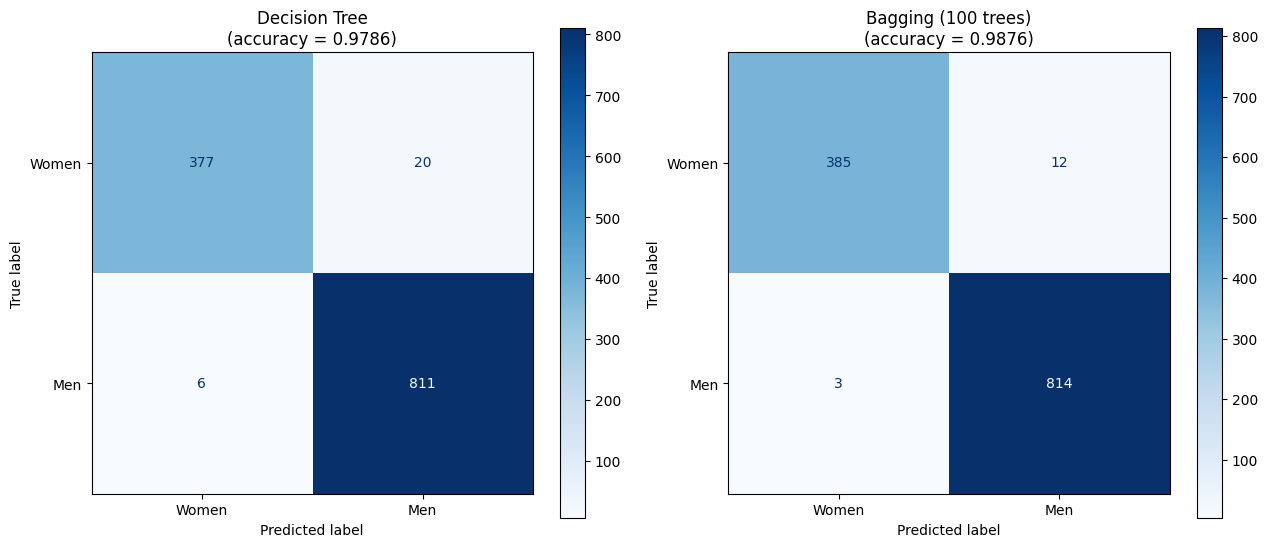

Decision Tree         : women labelled as men =  20 | men labelled as women =   6 | total errors = 26
Bagging (100 trees)   : women labelled as men =  12 | men labelled as women =   3 | total errors = 15


In [36]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, name in zip(axes, ["Decision Tree", "Bagging (100 trees)"]):
    ConfusionMatrixDisplay.from_predictions(y_test, predictions[name], labels=[0, 1],
                                            display_labels=class_names, ax=ax,
                                            cmap="Blues", values_format="d")
    ax.set_title(f"{name}\n(accuracy = {accuracy_score(y_test, predictions[name]):.4f})")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
plt.tight_layout()
plt.show()

for name in ["Decision Tree", "Bagging (100 trees)"]:
    tn, fp, fn, tp = confusion_matrix(y_test, predictions[name], labels=[0, 1]).ravel()
    print(f"{name:22s}: women labelled as men = {fp:3d} | men labelled as women = {fn:3d} | total errors = {fp + fn}")

summary of the comparison

In [37]:
acc_tree = accuracy_score(y_test, predictions["Decision Tree"])
acc_bag = accuracy_score(y_test, predictions["Bagging (100 trees)"])
err_tree = int((predictions["Decision Tree"] != y_test).sum())
err_bag = int((predictions["Bagging (100 trees)"] != y_test).sum())

baseline_name = "Always 'Men' (baseline)"
acc_base = accuracy_score(y_test, predictions[baseline_name])
print(f"Baseline 'always men' accuracy : {acc_base:.4f}")
print(f"Decision Tree test accuracy    : {acc_tree:.4f}  ({err_tree} errors out of {len(y_test)})")
print(f"Bagging test accuracy          : {acc_bag:.4f}  ({err_bag} errors out of {len(y_test)})")
change = (acc_bag - acc_tree) * 100
verdict = "improved" if change > 0 else ("did not change" if change == 0 else "reduced")
print(f"\nBagging {verdict} the test accuracy by {change:+.2f} percentage points "
      f"({err_tree - err_bag:+d} fewer errors).")
print(f"Cross-validation accuracy: tree {cv_tree.mean():.4f} +/- {cv_tree.std():.4f} "
      f"vs bagging {cv_bag.mean():.4f} +/- {cv_bag.std():.4f}")

Baseline 'always men' accuracy : 0.6730
Decision Tree test accuracy    : 0.9786  (26 errors out of 1214)
Bagging test accuracy          : 0.9876  (15 errors out of 1214)

Bagging improved the test accuracy by +0.91 percentage points (+11 fewer errors).
Cross-validation accuracy: tree 0.9763 +/- 0.0047 vs bagging 0.9870 +/- 0.0052


## Summary of Results

- **Comparison:** The output from the cell above specifies exactly how Bagging has altered the test accuracy, as well as the net change in the number of errors. To ensure a reliable assessment, cross-validation (calculating the mean and standard deviation across folds) and Out-of-Bag (OOB) evaluation were also employed.
- **Theoretical Expectation:** A single decision tree typically exhibits high variance. Bagging reduces this variance by averaging the predictions of 100 trees—each trained on a bootstrap sample—which generally leads to higher and more stable accuracy. If the observed difference is marginal (e.g., involving only a few samples), it should be attributed to noise.
- **Confusion Matrix:** This reveals whether a model is more prone to misclassifying women as men or men as women. Since the male class is approximately twice as large as the female class, the recall for the female class is typically slightly lower than that for the male class.
- **Limitations:** These results are based on data from U.S. military personnel and may not generalize to the broader population.